## Probability of filling as a function of number of dice

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import comb
import functools

In [2]:
FS = 16

In [3]:
@functools.lru_cache(maxsize=500)
def P_fill_given_N(N):
    A = [comb(N, i) * 2 ** (N + i) * P_fill_given_N(N - i) for i in range(1, N)]
    val = (1 / (6 ** N)) * (2 ** N + sum(A))
    return val

In [4]:
x = range(1, 7)
y = list(map(P_fill_given_N, x))

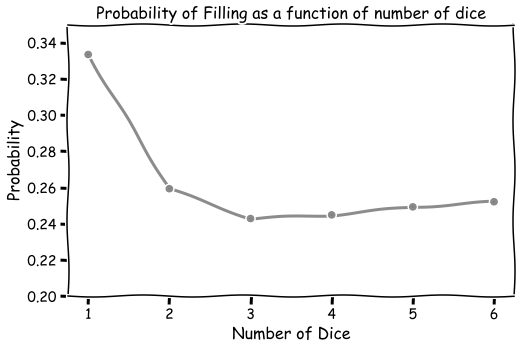

In [5]:
with plt.xkcd(scale=1, length=100, randomness=1):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(x, y, 'ko-', alpha=0.9, color='gray', lw=3)
    ax.set_xlabel('Number of Dice', fontsize=FS)
    ax.set_ylabel('Probability', fontsize=FS)
    ax.set_ylim([0.2, 0.35])
    ax.set_title('Probability of Filling as a function of number of dice', fontsize=FS)
    ax.grid(True)
    plt.show()

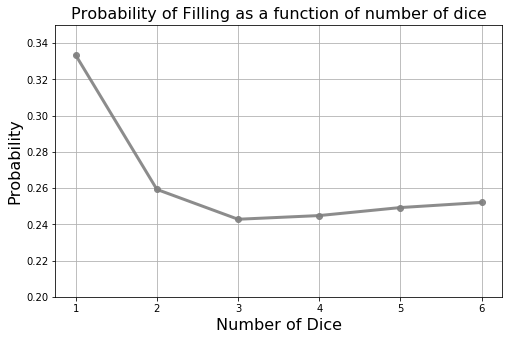

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(x, y, 'ko-', alpha=0.9, color='gray', lw=3)
ax.set_xlabel('Number of Dice', fontsize=FS)
ax.set_ylabel('Probability', fontsize=FS)
ax.set_ylim([0.2, 0.35])
ax.set_title('Probability of Filling as a function of number of dice', fontsize=FS)
ax.grid(True)
plt.show()

# Muss Buss

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from requests import Session
import pandas as pd
import time
from mussbot.mussbot import Player

### Create the player clients

In [ ]:
kwargs = dict(host='http://localhost:8080', game_number=None, wait=0.0, verbose=False)
p1 = Player(username='john', password='123', **kwargs)
p2 = Player(username='chris', password='123', **kwargs)

### Play a game

In [20]:
def check_if_players_are_in_same_game(players):
    msg = 'These players are not part of the same game.'
    assert len(set(player.game_number for player in players)) == 1, msg

def get_winner(players):
    check_if_players_are_in_same_game(players)
    for player in players[0].game.players:
        if player['winner']:
            return player['name']
    return False

def play_a_game(*players):
    '''
    Plays a game of Muss Buss.
    '''
    t0 = time.time()
    print('Starting the game.')
    n = 0
    while not get_winner(players):
        for player in players:
            player.take_turn()
            n += 1
    winner = get_winner(players)
    elapsed = (time.time() - t0)
    tps = n / elapsed
    msg = f'{winner} won!\n\nTime elapsed: {elapsed:.1f} seconds\nTotal turns: {n}\nTurns per second: {tps: .1f}'
    print(msg)

#### Start a new game

In [22]:
p1.new_game(['john', 'chris'])
p2.switch_games(p1.game_number)
print(p1)
print(p2)

(john) <GAME_6>: john, chris
(chris) <GAME_6>: john, chris


In [23]:
play_a_game(p1, p2)

Starting the game.
chris won!

Time elapsed: 12.7 seconds
Total turns: 340
Turns per second:  26.9
